# Single-cell 3-D genome reconstruction: NucDynamics and EMber

A single-cell Hi-C experiment gives a list of contacts — pairs of loci that were close in one nucleus.
This tutorial turns the contacts of one cell into an ensemble of whole-genome 3-D structures with the
two single-cell methods of `uchrom.recon.sc`, both running on the native engine `uchrom_recon`
(Rust; multi-core CPU or GPU): **NucDynamics** (`reconstruct_nucdyn`, a re-implementation of
Stevens et al. 2017) and **EMber** (`reconstruct_ember`, U-Chrom's noise-aware method).  You will read
the output `ChromData` (models are layers, not cells), measure how well the models agree with each
other and with the structures the authors published for the same cell, draw distance maps, and run the
command line.

**Data**: Stevens et al. 2017, *Nature* 544:59 (haploid mouse ES cell in G1, GEO GSE80280), Cell 1:
its contact file from GEO, `GSM2219497_Cell_1_contact_pairs.txt.gz` (`ds.fetch("stevens2017")` downloads the
files of the 8 cells once, 43 MB), and the authors' published 100 kb structures of the same cell from the
store of the public U-Chrom atlas, `ds.atlas("stevens2017_mesc")` (read over HTTP; only this cell is
fetched).  **Runtime**: about 2.5 min on a laptop with a GPU (Apple M-series, Metal); NucDynamics is stopped
at 400 kb particles here (its default schedule continues to 100 kb).

In [1]:
import itertools
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from chromdata import ChromData
import uchrom as uc
import uchrom.datasets as ds
from uchrom.recon.sc import reconstruct_ember, reconstruct_nucdyn
from uchrom.recon.sc.nucdyn import engine_info, load_contacts

plt.rcParams["figure.dpi"] = 90

OUT = Path("_out") / "reconstruction"; OUT.mkdir(parents=True, exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)

# Stevens 2017 Cell 1: the GEO contact file (ds.fetch downloads the 8 cells once, 43 MB)
PAIRS = ds.fetch("stevens2017") / "GSM2219497_Cell_1_contact_pairs.txt.gz"
CHROMS = [f"chr{i}" for i in range(1, 20)] + ["chrX"]
info = engine_info()
print(f"uchrom_recon {info['version']}; GPU: {info['gpu'] or 'none (CPU only)'}")

uchrom_recon 0.1.0; GPU: Apple M5 Pro (Metal, IntegratedGpu)


## The input: the contacts of one cell

`load_contacts` reads what the engine reads — here the GEO table of the cell (`chr_A pos_A chr_B pos_B`,
gzipped); `.pairs`, NCC files and DataFrames work too — and returns plain arrays.  Each contact is one
ligation event; a haploid cell has one copy of every chromosome, so every contact is a 3-D proximity
in the one structure we want (diploid, phased contacts are covered at the end).

111,838 contacts on 20 chromosomes; 90.5% intra-chromosomal, median separation 0.2 Mb


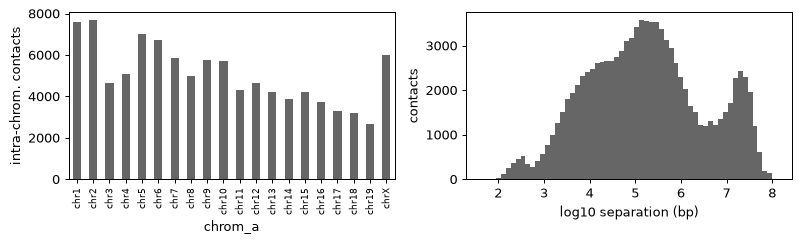

In [2]:
c = load_contacts(PAIRS)
contacts = pd.DataFrame({k: c[k] for k in ("chrom_a", "pos_a", "chrom_b", "pos_b")})
cis = (contacts["chrom_a"] == contacts["chrom_b"]).to_numpy()
sep = (contacts["pos_b"] - contacts["pos_a"]).abs()[cis]
print(f"{len(contacts):,} contacts on {contacts['chrom_a'].nunique()} chromosomes; "
      f"{cis.mean():.1%} intra-chromosomal, median separation {sep.median() / 1e6:.1f} Mb")

fig, ax = plt.subplots(1, 2, figsize=(9, 2.8))
contacts.loc[cis, "chrom_a"].value_counts().reindex(CHROMS).plot.bar(ax=ax[0], color="0.4")
ax[0].set_ylabel("intra-chrom. contacts"); ax[0].tick_params(axis="x", labelsize=7)
ax[1].hist(np.log10(sep[sep > 0]), bins=60, color="0.4")
ax[1].set_xlabel("log10 separation (bp)"); ax[1].set_ylabel("contacts")
fig.tight_layout()

## NucDynamics: an ensemble of structures

NucDynamics represents every chromosome as a chain of particles and anneals it under the contact
restraints, hierarchically: the particles shrink stage by stage (default 8 → 4 → 2 → 0.4 → 0.2 →
0.1 Mb), each stage starting from the previous one; contacts that are isolated or violated at a stage
are dropped.  All `n_models` models (different random starts) are computed together — in parallel on
the CPU (f64, all cores), in one batch on the GPU (f32; `device="auto"` takes the GPU when there is one).
The default protocol `"nuc_dynamics_2017"` is the code behind the published 2017 structures.

To keep this tutorial short we stop at **400 kb** particles (`particle_sizes`); the annealing per
stage is the default.  Drop `particle_sizes=` for the full 100 kb schedule (about 4 × longer).

In [3]:
t0 = time.time()
nd = reconstruct_nucdyn(PAIRS, n_models=10, device="auto", seed=1,
                        particle_sizes=(8e6, 4e6, 2e6, 4e5), cell_id="Cell_1")
t_nd = time.time() - t0
print(f"NucDynamics: {nd.uns['nucdyn']['n_models']} models x {nd.n_spots:,} particles "
      f"in {t_nd:.0f} s on the {nd.uns['nucdyn']['device'].upper()}")
nd.results["nucdyn.stages"][["stage", "particle_size", "n_particles", "n_contacts", "n_restraints",
                             "seconds_dynamics"]]

NucDynamics: 10 models x 6,464 particles in 34 s on the GPU


,stage,particle_size,n_particles,n_contacts,n_restraints,seconds_dynamics
0,0,8000000.0,358,111673,2950,3.920115
1,1,4000000.0,687,111673,5695,4.507881
2,2,2000000.0,1324,111673,10626,6.346879
3,3,400000.0,6464,111673,41535,18.696803


The stage log is stored with the result (`cd.results["nucdyn.stages"]`, with the engine parameters as
provenance: `cd.results.record("nucdyn.stages").params`): `n_contacts` counts the contacts in use
(isolated contacts are removed before the first stage — only 165 of this cell's 111,838, as the GEO file is
already filtered — and contacts violated by a stage's structures before the next one), `n_restraints` counts
the particle pairs they bind.

## What the output holds

The result is an ordinary `ChromData`:

* **spots / bins** — one spot per particle; `bins` are the particles' genomic intervals (2017
  convention: the particle at sequence position *p* collects the contacts in (*p* − size, *p*]).
* **traces** — one per chromosome (20 here, chr1–19 and chrX; a chromosome without usable contacts
  would get a single particle).  **cells** — the ensemble is *one* cell (`cell_id="Cell_1"`): the
  models are **not** cells.
* **coords** = model 0 and **layers** `model_0` … `model_9` = every model, all in the same spot order,
  so the whole ensemble travels with the object.  Units: particle radii (`uns["xyz_unit"]`).
* **uns["nucdyn"]** — engine, device, protocol, seed, timing, citation.

In [4]:
print(nd)
print("layers:", list(nd.layers))
print({k: nd.uns["nucdyn"][k] for k in ("protocol", "device", "n_models", "seed", "particle_size")})
nd.spots_with_loci().head(3)

ChromData: n_spots=6464, n_traces=20, n_cells=1, n_bins=6464
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'bin_id']
  layers:  ['model_0', 'model_1', 'model_2', 'model_3', 'model_4', 'model_5', 'model_6', 'model_7', 'model_8', 'model_9']
  results: ['nucdyn.stages']
  uns:     ['xyz_unit', 'nucdyn']
layers: ['model_0', 'model_1', 'model_2', 'model_3', 'model_4', 'model_5', 'model_6', 'model_7', 'model_8', 'model_9']
{'protocol': 'nuc_dynamics_2017', 'device': 'gpu', 'n_models': 10, 'seed': 1, 'particle_size': 400000}


,chrom,start,end,trace_id,cell_id,bin_id
0,chr1,2400000,2800000,0,Cell_1,0
1,chr1,2800000,3200000,0,Cell_1,1
2,chr1,3200000,3600000,0,Cell_1,2


In [5]:
path = OUT / "cell1_nucdyn_400kb.chromdata.zarr"
nd.write(path)
back = ChromData.read(path)
print(f"wrote {path}; read back {back.n_spots:,} spots, {len(back.layers)} model layers")

wrote _out/reconstruction/cell1_nucdyn_400kb.chromdata.zarr; read back 6,464 spots, 10 model layers


## Model-to-model agreement

How well do the contacts determine the structure?  Stevens et al. measured it as the **RMSD between
models after optimal superposition** (in particle radii; a model and its mirror image fit the contacts
equally well, so we allow the reflection).  A scale-free alternative is the **correlation of the
distance matrices**, chromosome by chromosome.

In [6]:
def kabsch_rmsd(a, b):
    # RMSD after optimal superposition of a onto b (rotation, mirror image allowed)
    a = a - a.mean(0); b = b - b.mean(0)
    u, _, vt = np.linalg.svd(a.T @ b)
    return min(float(np.sqrt((((a @ (u @ np.diag([1, 1, d]) @ vt)) - b) ** 2).sum(1).mean()))
               for d in (1.0, -1.0))


def chrom_distance_r(a, b, chrom, min_particles=10):
    # median over chromosomes of the Pearson r between the two models' distance matrices
    rs = []
    for ch in np.unique(chrom):
        i = np.flatnonzero(chrom == ch)
        if len(i) < min_particles:
            continue
        iu = np.triu_indices(len(i), 1)
        da = np.linalg.norm(a[i, None] - a[None, i], axis=-1)[iu]
        db = np.linalg.norm(b[i, None] - b[None, i], axis=-1)[iu]
        rs.append(np.corrcoef(da, db)[0, 1])
    return float(np.median(rs))


def ensemble(cd):
    return [np.asarray(cd.layers[k]) for k in sorted(cd.layers)]


def agreement(cd, n_r=4):
    models = ensemble(cd)
    chrom = cd.spots_with_loci()["chrom"].astype(str).to_numpy()
    rmsd = np.zeros((len(models), len(models)))
    for i, j in itertools.combinations(range(len(models)), 2):
        rmsd[i, j] = rmsd[j, i] = kabsch_rmsd(models[i], models[j])
    pairs = list(itertools.combinations(range(n_r), 2))
    r = [chrom_distance_r(models[i], models[j], chrom) for i, j in pairs]
    per_chrom = [kabsch_rmsd(models[i][chrom == ch], models[j][chrom == ch])
                 for i, j in pairs for ch in np.unique(chrom) if (chrom == ch).sum() >= 10]
    return rmsd, float(np.median(r)), float(np.median(per_chrom))


rmsd_nd, r_nd, rc_nd = agreement(nd)
iu = np.triu_indices(len(rmsd_nd), 1)
print(f"NucDynamics 400 kb: genome-wide RMSD {rmsd_nd[iu].mean():.2f} radii (range {rmsd_nd[iu].min():.2f}-"
      f"{rmsd_nd[iu].max():.2f}); per chromosome: RMSD {rc_nd:.2f} radii, distance-matrix r {r_nd:.4f}")

NucDynamics 400 kb: genome-wide RMSD 0.28 radii (range 0.14-0.39); per chromosome: RMSD 0.10 radii, distance-matrix r 0.9997


Each chromosome comes out practically the same in every model (per-chromosome RMSD of a tenth of a
particle radius), and so does the arrangement of the chromosomes: the genome-wide RMSD is only a little
larger, below 0.4 radii for every pair of models — the trans contacts (a tenth of this cell's contacts) place
the chromosomes relative to each other consistently.  A model with a different chromosome arrangement would
stand out in the matrix as a bright row:

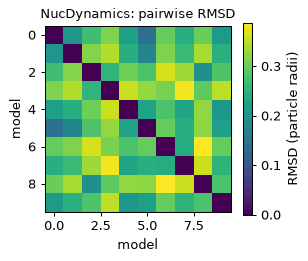

In [7]:
fig, ax = plt.subplots(figsize=(3.6, 3))
im = ax.imshow(rmsd_nd, cmap="viridis")
ax.set_xlabel("model"); ax.set_ylabel("model"); ax.set_title("NucDynamics: pairwise RMSD", fontsize=10)
fig.colorbar(im, ax=ax, label="RMSD (particle radii)")
fig.tight_layout()

## CPU or GPU

`device="cpu"` runs in double precision on all cores (`n_threads=0`), and a seed gives bit-identical
models for any thread count; `device="gpu"` runs in single precision through wgpu (Metal on macOS,
Vulkan on Linux) and batches all models.  The whole genome is slow on a laptop CPU, so we compare the
devices on one chromosome — `genome_ranges` keeps only the contacts inside the given ranges — with the
full default schedule down to 100 kb.  The two devices do not give the same models (different arithmetic
on a chaotic trajectory), but models of the same quality.

In [8]:
one = dict(genome_ranges="chr19", n_models=4, seed=1, key_added=None)
t0 = time.time(); cpu_a = reconstruct_nucdyn(PAIRS, device="cpu", **one); t_cpu = time.time() - t0
cpu_b = reconstruct_nucdyn(PAIRS, device="cpu", **one)
same = all(np.array_equal(cpu_a.layers[k], cpu_b.layers[k]) for k in cpu_a.layers)
print(f"chr19, {cpu_a.n_spots} particles x 4 models -- CPU: {t_cpu:.0f} s; same seed twice -> identical models: {same}")
if engine_info()["gpu"]:
    t0 = time.time(); gpu_a = reconstruct_nucdyn(PAIRS, device="gpu", **one); t_gpu = time.time() - t0
    print(f"GPU: {t_gpu:.0f} s; CPU vs GPU model 0, RMSD {kabsch_rmsd(cpu_a.coords, gpu_a.coords):.2f} radii "
          f"(CPU model 0 vs 1: {kabsch_rmsd(cpu_a.layers['model_0'], cpu_a.layers['model_1']):.2f})")

chr19, 585 particles x 4 models -- CPU: 19 s; same seed twice -> identical models: True


GPU: 15 s; CPU vs GPU model 0, RMSD 0.80 radii (CPU model 0 vs 1: 0.56)


## EMber: noise-aware reconstruction

EMber is the native engine's protocol `"robust"`.  It keeps the NucDynamics particle model but treats
every contact as either a true proximity or a false contact (rate ε): before each stage the contact
restraints are re-weighted by their posterior probability of being true, with ε and the contact-kernel
width learned by EM from the current structures; it uses a short annealing schedule, a sampling stage
at finite temperature (calibrated ensembles) and goes to 100 kb by default.  EMber was pre-registered,
frozen and tested once against NucDynamics (`benchmarks/screcon/PREREG.md`, `TEST_RESULTS.md`): use it
with its defaults.  `uc.tl.reconstruct_sc(...)` is the same call.

In [9]:
t0 = time.time()
em = reconstruct_ember(PAIRS, n_models=10, device="auto", seed=1, cell_id="Cell_1")
t_em = time.time() - t0
print(f"EMber: {em.uns['ember']['n_models']} models x {em.n_spots:,} particles (100 kb) in {t_em:.0f} s")
em.write(OUT / "cell1_ember.chromdata.zarr")
log = em.results["ember.em"]
log[["stage", "particle_size", "segment", "eps", "s", "mean_w"]].tail(6)

EMber: 10 models x 25,724 particles (100 kb) in 13 s


,stage,particle_size,segment,eps,s,mean_w
6,4,200000.0,0,0.0001,0.5,0.999999
7,4,200000.0,1,0.0001,0.5,1.000000
8,5,100000.0,0,0.0001,0.5,0.999999
9,5,100000.0,1,0.0001,0.5,1.000000
10,6,100000.0,0,0.0001,0.5,0.999999
11,6,100000.0,1,0.0001,0.5,1.000000


`cd.results["ember.em"]` is the EM log (one row per update: false-contact rate `eps`, kernel width `s`,
mean weight); `cd.results["ember.contact_weights"]` holds the final posterior weight of every input
contact (in `load_contacts` order; NaN = removed as isolated before the structure was computed).

In [10]:
w = em.results["ember.contact_weights"]
kept = np.isfinite(w)
print(f"learned false-contact rate eps = {log['eps'].iloc[-1]:.1e}")
print(f"contacts: {kept.sum():,} used, {(~kept).sum():,} removed as isolated; "
      f"weight < 0.5 for {(w[kept] < 0.5).sum():,} ({(w[kept] < 0.5).mean():.2%})")

learned false-contact rate eps = 1.0e-04
contacts: 111,646 used, 192 removed as isolated; weight < 0.5 for 0 (0.00%)


This cell is clean: the authors' processing already removed most noise, so EMber learns a
false-contact rate at its floor and keeps practically every contact at full weight — here it behaves
like NucDynamics with a much shorter schedule.  The re-weighting matters for noisier cells and
protocols (the pre-registered test compared it with NucDynamics on held-out contacts of Stevens cells
5–8 and on simulations with known structures: `benchmarks/screcon/TEST_RESULTS.md`).

How well do the final structures satisfy the contacts?  Map both ends of every used contact to their
particle (the first particle at or after the position) and measure the distance in model 0; a single
contact restrains its particles to 0.8–1.2 radii.

EMber model 0: median contact distance 1.37 radii; 61.9% within 1.5, 2.1% beyond 3 radii


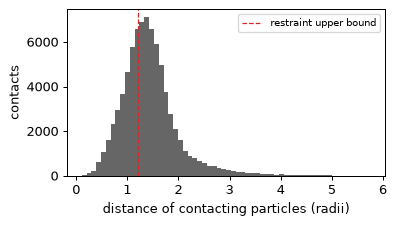

In [11]:
def particle_of(cd, chrom, pos):
    # spot index of the particle that holds each contact end (first particle at or after pos)
    loci = cd.spots_with_loci()
    lchrom = loci["chrom"].astype(str).to_numpy(); lend = loci["end"].to_numpy()
    out = np.full(len(pos), -1)
    for ch in np.unique(chrom):
        rows = np.flatnonzero(lchrom == ch)
        rows = rows[np.argsort(lend[rows])]
        m = np.flatnonzero(chrom == ch)
        k = np.searchsorted(lend[rows], pos[m], side="left")
        ok = k < len(rows)
        out[m[ok]] = rows[k[ok]]
    return out


ia = particle_of(em, c["chrom_a"].astype(str), c["pos_a"])
ib = particle_of(em, c["chrom_b"].astype(str), c["pos_b"])
use = kept & (ia >= 0) & (ib >= 0) & (ia != ib)
d = np.linalg.norm(em.coords[ia[use]] - em.coords[ib[use]], axis=1)
print(f"EMber model 0: median contact distance {np.median(d):.2f} radii; "
      f"{(d <= 1.5).mean():.1%} within 1.5, {(d > 3).mean():.1%} beyond 3 radii")
fig, ax = plt.subplots(figsize=(4.5, 2.6))
ax.hist(np.clip(d, 0, 6), bins=60, color="0.4")
ax.axvline(1.2, color="C3", ls="--", lw=1, label="restraint upper bound")
ax.set_xlabel("distance of contacting particles (radii)"); ax.set_ylabel("contacts"); ax.legend(fontsize=8)
fig.tight_layout()

In [12]:
rmsd_em, r_em, rc_em = agreement(em)
iu = np.triu_indices(len(rmsd_em), 1)
print(f"EMber 100 kb: genome-wide RMSD {rmsd_em[iu].mean():.2f} radii (range {rmsd_em[iu].min():.2f}-"
      f"{rmsd_em[iu].max():.2f}); per chromosome: RMSD {rc_em:.2f} radii, distance-matrix r {r_em:.4f}")

EMber 100 kb: genome-wide RMSD 1.02 radii (range 0.91-1.21); per chromosome: RMSD 0.76 radii, distance-matrix r 0.9949


RMSDs are in radii of the particles of each run (400 kb for NucDynamics here, 100 kb for EMber), so the
two numbers are not directly comparable.  EMber's last stage samples at finite temperature, so its
ensemble keeps the spread the contacts allow instead of collapsing to one annealing minimum — here most
of the spread is inside the chromosomes (per-chromosome RMSD close to the genome-wide one), not in their
arrangement.

## Comparison with the published structures of the same cell

Stevens et al. deposited ten 100 kb NucDynamics models per cell (computed with their original code from
the same GEO contact file).  The atlas store holds them
as one cell per GEO cell (model 1 in `coords`, models 2–10 as layers).  We average the published
particles onto ours (a published particle at position *q* goes to our particle whose interval holds *q*),
then compare distance matrices chromosome by chromosome.  This measures how well the published result is
reproduced — the published models come from the same algorithm, so it is not an accuracy score against
a ground truth.

In [13]:
pub = ds.atlas("stevens2017_mesc").get_cell("Cell_1")   # the public atlas, backed over HTTP: reads this cell only
pub_models = [np.asarray(pub.coords)] + [np.asarray(pub.layers[f"model_{k}"]) for k in range(2, 11)]
print(pub)


def on_particles(cd, ref, ref_models):
    # reference coordinates averaged onto the particles of cd; returns (our spot rows, [models])
    loci, rl = cd.spots_with_loci(), ref.spots_with_loci()
    lchrom = loci["chrom"].astype(str).to_numpy()
    lstart, lend = loci["start"].to_numpy(), loci["end"].to_numpy()
    target = np.full(len(rl), -1)
    rchrom, q = rl["chrom"].astype(str).to_numpy(), rl["start"].to_numpy()   # published particle position
    for ch in np.unique(rchrom):
        rows = np.flatnonzero(lchrom == ch)
        rows = rows[np.argsort(lend[rows])]
        m = np.flatnonzero(rchrom == ch)
        k = np.searchsorted(lend[rows], q[m], side="left")
        ok = k < len(rows)
        hit = rows[k[ok]]
        inside = lstart[hit] < q[m][ok]
        target[m[ok][inside]] = hit[inside]
    ok = target >= 0
    ours = np.unique(target[ok])
    grp = pd.Index(ours).get_indexer(target[ok])
    n = np.bincount(grp, minlength=len(ours))[:, None]
    avg = [np.stack([np.bincount(grp, weights=X[ok, a], minlength=len(ours)) for a in range(3)], 1) / n
           for X in ref_models]
    return ours, avg


def vs_published(cd, n_ours=3, n_pub=3):
    rows, ref = on_particles(cd, pub, pub_models[:n_pub])
    chrom = cd.spots_with_loci()["chrom"].astype(str).to_numpy()[rows]
    models = ensemble(cd)[:n_ours]
    return float(np.mean([chrom_distance_r(m[rows], r, chrom) for m in models for r in ref])), len(rows)


rows = []
for name, cd, res in (("NucDynamics", nd, "400 kb"), ("EMber", em, "100 kb")):
    r_pub, n = vs_published(cd)
    rows.append({"method": name, "resolution": res, "particles matched": n, "r vs published": r_pub})
pp = [chrom_distance_r(a, b, pub.spots_with_loci()["chrom"].astype(str).to_numpy())
      for a, b in itertools.combinations(pub_models[:4], 2)]
rows.append({"method": "published vs published", "resolution": "100 kb",
             "particles matched": pub.n_spots, "r vs published": float(np.median(pp))})
summary = pd.DataFrame(rows)
summary.round(3)

ChromData: n_spots=25724, n_traces=20, n_cells=1, n_bins=25734
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'bin_id']
  cells:   ['gsm', 'n_contacts', 'cell_type'] (1 cells)
  layers:  ['model_2', 'model_3', 'model_4', 'model_5', 'model_6', 'model_7', 'model_8', 'model_9', 'model_10']
  uns:     ['genome_assembly', 'xyz_unit', 'source', 'coordinate_status', 'linked_cool', 'linked_scool']


,method,resolution,particles matched,r vs published
0,NucDynamics,400 kb,6445,0.985
1,EMber,100 kb,25724,0.983
2,published vs published,100 kb,25724,0.999


Both reconstructions recover the published structure of this cell closely (per-chromosome
distance-matrix r ≈ 0.98); the published models agree with each other at ≈ 0.999, the ceiling for
this measure.  The input is the same contact file, so the remaining difference comes from the coarser
particles of the NucDynamics run here (400 kb), single precision on the GPU and, for EMber, its own
schedule and finite-temperature sampling.

## Distance maps

`cd.get_chrom(name)` subsets one chromosome (layers included) and `compute_distances()` gives its
particle-to-particle distance matrix.  Below: chromosome 19 in the published model, NucDynamics
(400 kb), EMber model 0 and the EMber ensemble median (100 kb), with the input contacts of the
chromosome as dots in the last panel.

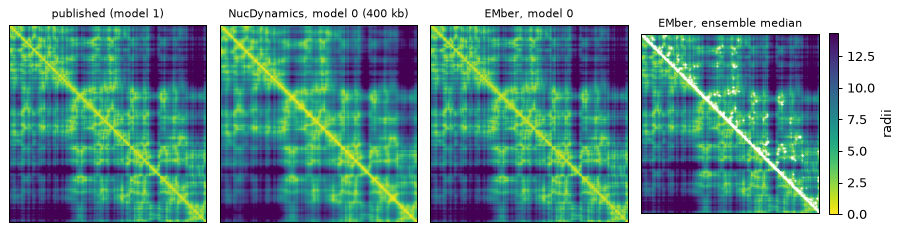

In [14]:
CH = "chr19"
pub19, nd19, em19 = pub.get_chrom(CH), nd.get_chrom(CH), em.get_chrom(CH)
D_em = np.stack([np.linalg.norm(X[:, None] - X[None], axis=-1) for X in ensemble(em19)])
panels = [("published (model 1)", pub19.compute_distances()),
          ("NucDynamics, model 0 (400 kb)", nd19.compute_distances()),
          ("EMber, model 0", D_em[0]), ("EMber, ensemble median", np.median(D_em, 0))]
fig, axes = plt.subplots(1, 4, figsize=(10, 2.9))
for ax, (title, D) in zip(axes, panels):
    im = ax.imshow(D, cmap="viridis_r", vmax=np.percentile(D, 95))
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes[-1], fraction=0.046, label="radii")
on = (contacts["chrom_a"] == CH).to_numpy() & (contacts["chrom_b"] == CH).to_numpy()
loci19 = em19.spots_with_loci()
ka = np.searchsorted(np.sort(loci19["end"].to_numpy()), contacts.loc[on, "pos_a"].to_numpy())
kb = np.searchsorted(np.sort(loci19["end"].to_numpy()), contacts.loc[on, "pos_b"].to_numpy())
axes[-1].scatter(np.maximum(ka, kb), np.minimum(ka, kb), s=0.2, c="w", alpha=0.5, rasterized=True)
axes[-1].set_xlim(0, len(loci19) - 1); axes[-1].set_ylim(len(loci19) - 1, 0)
fig.tight_layout()

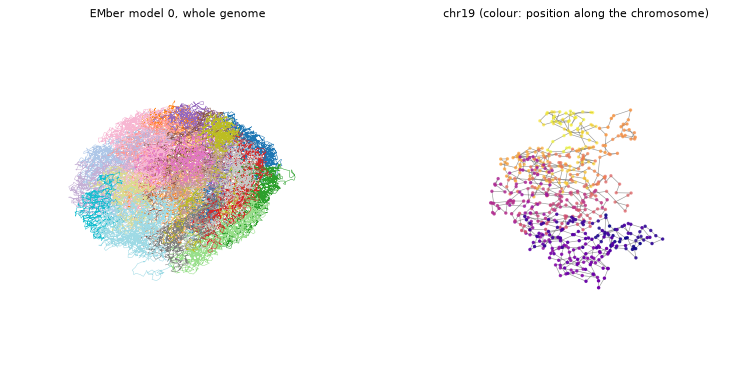

In [15]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers the 3-D projection)

loci = em.spots_with_loci()
fig = plt.figure(figsize=(9, 4.2))
ax = fig.add_subplot(1, 2, 1, projection="3d")
cmap = plt.get_cmap("tab20")
for k, ch in enumerate(CHROMS):
    X = em.coords[(loci["chrom"] == ch).to_numpy()]
    ax.plot(*X.T, lw=0.4, color=cmap(k % 20))
ax.set_title("EMber model 0, whole genome", fontsize=9); ax.set_axis_off()
ax = fig.add_subplot(1, 2, 2, projection="3d")
X = em19.coords
ax.plot(*X.T, lw=0.5, color="0.6")
ax.scatter(*X.T, c=np.arange(len(X)), cmap="plasma", s=3)
ax.set_title(f"{CH} (colour: position along the chromosome)", fontsize=9); ax.set_axis_off()
fig.tight_layout()

## Command line

`python -m uchrom.recon.sc.nucdyn IN OUT` runs the same reconstruction from a file and writes the
ensemble (`.chromdata.zarr` / `.cdz`; `.csv` = model 0 only).  Options are the function's keywords:
`--n_models`, `--device`, `--seed`, `--protocol` (`robust` = EMber), `--size_steps` (particle sizes in
Mb), `--genome_ranges` (e.g. `chr19`) and engine parameters.  A quick 8 → 2 Mb run:

In [16]:
out = OUT / "cell1_cli.chromdata.zarr"
cmd = [sys.executable, "-m", "uchrom.recon.sc.nucdyn", str(PAIRS), str(out),
       "--n_models=4", "--device=auto", "--seed=1", "--size_steps=[8,4,2]"]
t0 = time.time()
run = subprocess.run(cmd, capture_output=True, text=True)
print("$ python", " ".join(cmd[1:]).replace(str(PAIRS.parent), "$(python -m uchrom.datasets path stevens2017)"))
print(f"exit code {run.returncode}, {time.time() - t0:.0f} s")
cli = ChromData.read(out)
print(f"{out}: {cli.n_spots:,} particles x {len(cli.layers)} models, cell_id "
      f"{cli.spots['cell_id'].iloc[0]!r} (from the output file name), protocol {cli.uns['nucdyn']['protocol']}")

$ python -m uchrom.recon.sc.nucdyn $(python -m uchrom.datasets path stevens2017)/GSM2219497_Cell_1_contact_pairs.txt.gz _out/reconstruction/cell1_cli.chromdata.zarr --n_models=4 --device=auto --seed=1 --size_steps=[8,4,2]
exit code 0, 12 s
_out/reconstruction/cell1_cli.chromdata.zarr: 1,324 particles x 4 models, cell_id 'cell1_cli' (from the output file name), protocol nuc_dynamics_2017


## Notes

* **Resolution and runtime**: NucDynamics' cost grows with the number of particles and the annealing
  steps (500 × 100 per stage by default); EMber's schedule is about 20 × shorter per stage.  Here
  NucDynamics took about half a minute for 400 kb and EMber about 15 s for 100 kb on the GPU.  On a
  CPU-only machine, use fewer models or a coarser final size.
* **Phased (diploid) input**: hickit `.pairs` with `phase0` / `phase1` columns or Dip-C `.con` files are
  reconstructed as a diploid genome (one chain per chromosome copy, traces `chr1(pat)` / `chr1(mat)`);
  EMber then infers the copy of every contact with an unphased end (`results["ember.imputed_phase"]`).
* **Citation**: NucDynamics — Stevens et al. 2017, *Nature* 544:59 (doi:10.1038/nature21429); EMber is
  U-Chrom's own method (the citation string is in `uns["ember"]["citation"]`).

## Next steps

* `bulk_reconstruction` — 3-D structures from bulk Hi-C: MDS and IGM population deconvolution.
* `gem_fish_reconstruction` — Hi-C and chromatin-tracing distances together (GEM-FISH).
* `plotting_and_browser` — look at the reconstructed structures interactively.
* `chromdata_basics` / `chromdata_stores` — the object and the `.chromdata.zarr` files written here.